In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
zd = pd.read_csv(r'C:\Users\Trevo\Downloads\python_works\Zomato_DA\Zomato-data-.csv')

In [12]:
zd.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [13]:
#Making a function to remove the denominator characters
def Zom_handle(value):
    value=str(value).split('/');
    value = value[0];
    return float(value)

zd['rate'] = zd['rate'].apply(Zom_handle)
zd.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [14]:
#Get a summary of the dataframe
zd.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


Text(0.5, 0, 'Type of Restaurant')

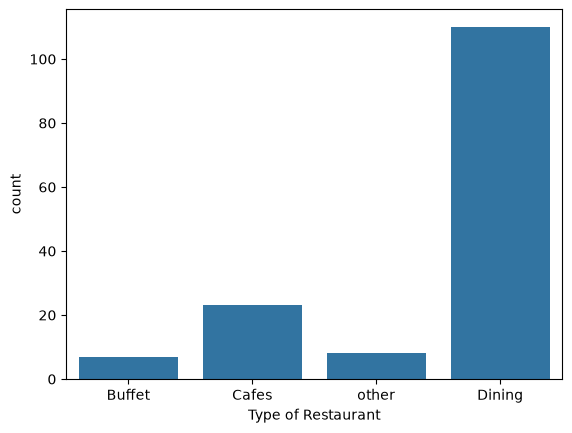

In [ ]:
#Using the seaborn module to look into popular restaurant categories
sns.countplot(x=zd['listed_in(type)'])
plt.xlabel("Type of Restaurant")

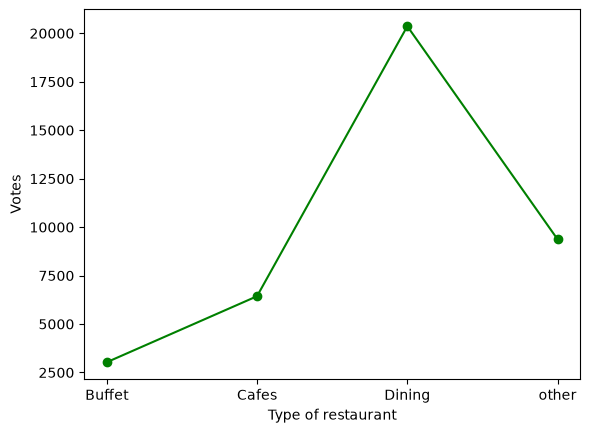

In [26]:
#Looking into votes submitted for each category
group_zd = zd.groupby('listed_in(type)')['votes'].sum()
result = pd.DataFrame({'votes': group_zd})
plt.plot(result, c='green', marker='o')
plt.xlabel('Type of restaurant')
plt.ylabel('Votes')
plt.savefig("votes_for_restaurants.png")

In [18]:
#Time to see which of the restaurats had the highest number of votes
max_votes = zd['votes'].max()
rest_max_votes = zd.loc[zd['votes'] == max_votes, 'name']
print('Here are restaurants with the highest votes: ')
print(rest_max_votes)

Here are restaurants with the highest votes: 
38    Empire Restaurant
Name: name, dtype: str


<Axes: xlabel='online_order', ylabel='count'>

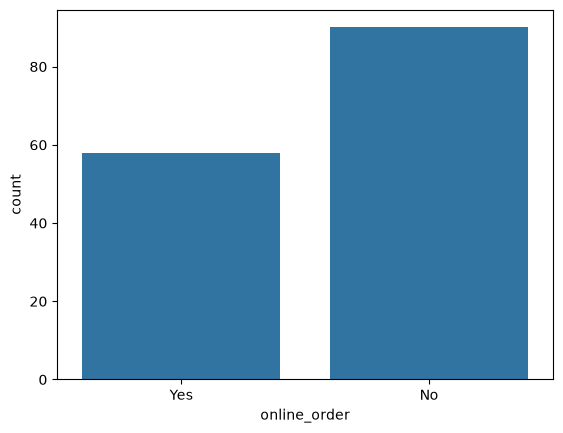

In [19]:
sns.countplot(x=zd['online_order'])

It would seem most restaurants don't accept online orders.

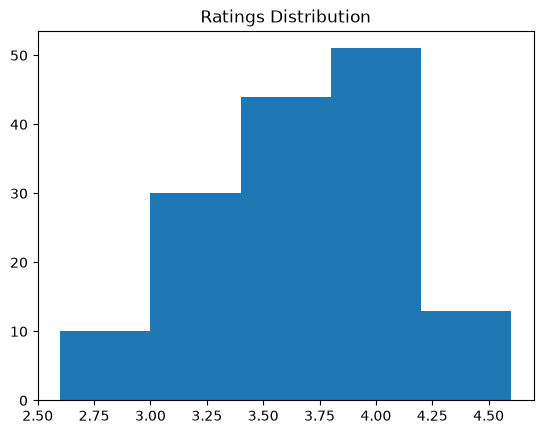

In [20]:
plt.hist(zd['rate'], bins=5)
plt.title('Ratings Distribution')
plt.show()

Majority of these ratings tend to range between 3.5 to 4.

<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

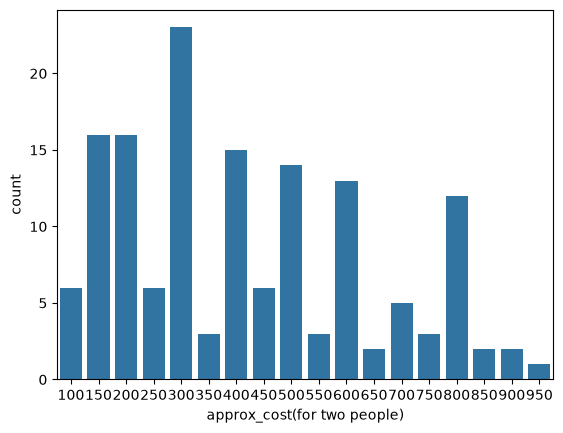

In [21]:
#checking the approximate cost for couples
couple_zd = zd['approx_cost(for two people)']
sns.countplot(x=couple_zd)

Most couples seem to frequent restaurants that cost them around 300 rupees (or about $3).

<Axes: xlabel='online_order', ylabel='rate'>

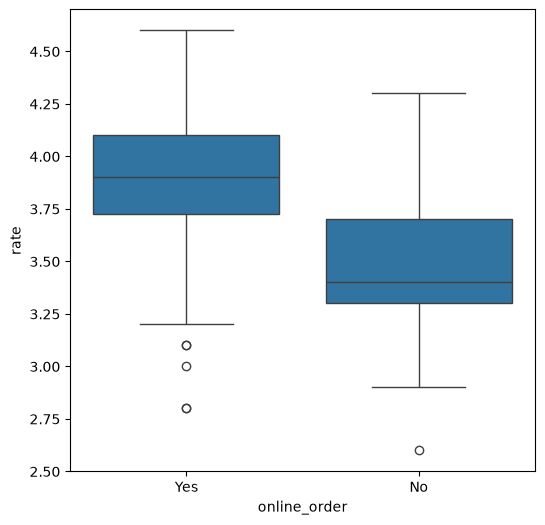

In [22]:
#Comparing ratings beween restaurants that accept online orders vs restaurants that don't
plt.figure(figsize= (6,6))
sns.boxplot(x= 'online_order', y='rate', data = zd)

Restaurants that don't accept online orders tend to also receive lower ratings.

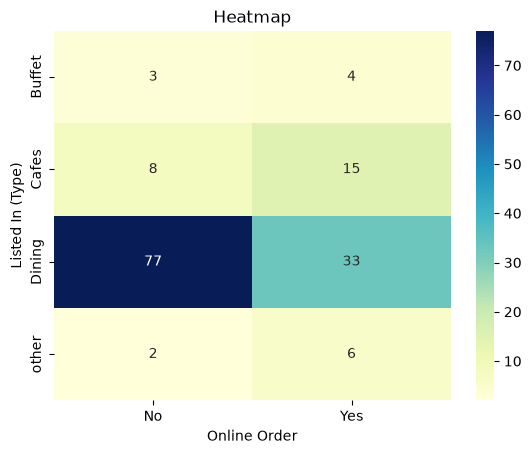

In [27]:
#Finding the relationships with order types and restaurant types
#We'll create a pivot table that counts restaurants by type and online order by availability
pivot = zd.pivot_table(index='listed_in(type)', columns='online_order', aggfunc='size', fill_value=0)
sns.heatmap(pivot, annot=True, cmap='YlGnBu', fmt='d')
plt.title('Heatmap')
plt.xlabel('Online Order')
plt.ylabel('Listed In (Type)')
plt.savefig('order_heatmap.png')
plt.show()

From the data given, it can be assumed that dining restaurants mostly accept offline orders while cafes mostly accept online orders. It would seem that clients largely prefer ordering in-person at restaurants, but prefer ordering online in any other type of restaurant. Why this is can be explored later.